In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder

In [2]:
# Step 1: Load dataset
df = pd.read_csv("Salary_data.csv")
print(df.head())

   YearsExperience  Salary Department
0              1.1   39343         IT
1              1.3   46205         HR
2              1.5   37731    Finance
3              2.0   43525         HR
4              2.2   39891    Finance


In [5]:
# Apply LabelEncoder to categorical column
le = LabelEncoder()
df['Department_Code'] = le.fit_transform(df['Department'])
print(df.head())

   YearsExperience  Salary Department  Department_Code
0              1.1   39343         IT                2
1              1.3   46205         HR                1
2              1.5   37731    Finance                0
3              2.0   43525         HR                1
4              2.2   39891    Finance                0


In [7]:
# Features and target
X = df[['YearsExperience', 'Department_Code']]
y = df['Salary']

In [8]:
# Step 3: Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
# Step 4: Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [10]:
# Step 5: Make predictions
y_pred = model.predict(X_test)

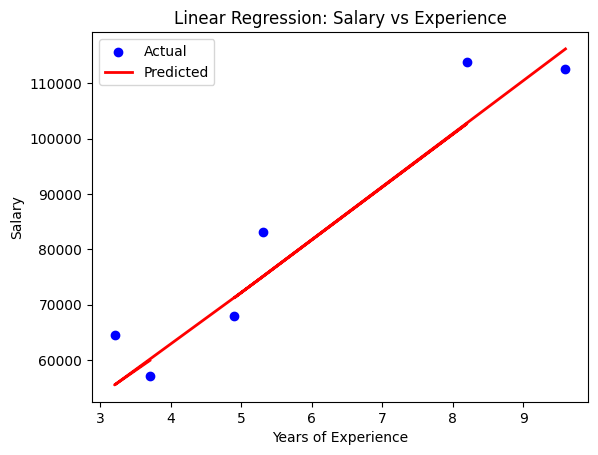

In [11]:
# Step 6: Visualize results
plt.scatter(X_test['YearsExperience'], y_test, color='blue', label='Actual')
plt.plot(X_test['YearsExperience'], y_pred, color='red', linewidth=2, label='Predicted')
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression: Salary vs Experience")
plt.legend()
plt.show()

In [16]:
# Predict salary for 7.5 years of experience in IT department
new_data = pd.DataFrame({'YearsExperience':[7.5], 'Department_Code':[le.transform(['IT'])[0]]})
predicted_salary = model.predict(new_data)

print(f"Predicted salary for 7.5 years of experience in IT: {predicted_salary[0]:.2f}")

Predicted salary for 7.5 years of experience in IT: 96406.28
